# Week 2+3: Turnover per weekday

**Question:** On which weekdays should the branch bake more (or less) of each product group, and how sure can we be? (Operations manager, canvas block 1.)

**What this notebook shows:** the average daily turnover per weekday, Monday to Sunday, with a 95 % confidence interval, for all products together and for each of the six product groups.

**Data:** `umsatzdaten_gekuerzt.csv`, 01.07.2013–31.07.2018. Turnover (`Umsatz`) is revenue in EUR, not the number of pieces sold.

## 1. Load the data

We read the sales file directly from the course repository (URL from `AGENTS.md`). We use **pandas** for tables, **scipy** for the confidence interval and **matplotlib** for the charts. The raw data is only read, never changed.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"

sales = pd.read_csv(DATA_URL + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])

print(f"{len(sales)} rows, columns: {list(sales.columns)}")
print(f"Period: {sales['Datum'].min().date()} to {sales['Datum'].max().date()}")
sales.head()

9334 rows, columns: ['id', 'Datum', 'Warengruppe', 'Umsatz']
Period: 2013-07-01 to 2018-07-31


,id,Datum,Warengruppe,Umsatz
0,1307011,2013-07-01,1,148.828353
1,1307021,2013-07-02,1,159.793757
2,1307031,2013-07-03,1,111.885594
3,1307041,2013-07-04,1,168.864941
4,1307051,2013-07-05,1,171.280754


Each row is the turnover of **one product group on one day** (`Datum` = date, `Warengruppe` = product group 1–6, `Umsatz` = turnover in EUR; `id` is not needed).

Next we give the group numbers readable names and count how many days with sales each group has. Seasonal bread is only sold in winter, so it has far fewer days, and its results will be less certain.

In [2]:
GROUP_NAMES = {
    1: "Bread",
    2: "Rolls",
    3: "Croissants",
    4: "Confectionery",
    5: "Cakes",
    6: "Seasonal bread",
}
sales["group"] = sales["Warengruppe"].map(GROUP_NAMES)

# How many days with sales does each product group have?
sales.groupby(["Warengruppe", "group"]).size().rename("days with sales").to_frame()

,,days with sales
Warengruppe,group,
1,Bread,1819
2,Rolls,1819
3,Croissants,1819
4,Confectionery,1766
5,Cakes,1819
6,Seasonal bread,292


## 2. Check the data

Before we compute anything, we check that the data looks the way we expect it to. A **check** (`assert`) stops the notebook with an error if a condition is not met, so a problem cannot slip through unnoticed.

- Each combination of date and product group must occur only once (otherwise we would count a day twice).
- There must be no missing turnover values.
- Turnover must not be negative.

In [3]:
assert not sales.duplicated(["Datum", "Warengruppe"]).any(), "a date/product group combination occurs twice"
assert sales["Umsatz"].notna().all(), "missing turnover values"
assert (sales["Umsatz"] >= 0).all(), "negative turnover"
assert sales["group"].notna().all(), "unknown product group number"
print("All checks passed.")

All checks passed.


## 3. Add up the turnover per day

We want the turnover of a **day**, not of a single row. We therefore *group* the rows by date and *sum* the turnover (pandas: `groupby(...).sum()`).

- **All products:** we sum all product groups of a day, so we get one number per day for the whole branch.
- **Per product group:** we sum per date *and* product group. Because each date/group combination occurs only once (see check above), this does not change the numbers, but it makes the step explicit and would still be correct if the data contained several rows per day.

*Days that are not in the file at all (e.g. when the branch was closed) are simply left out. We do not fill them with 0, because a missing day is not a day with zero sales.* On days where a group has no row (e.g. seasonal bread in summer), the day total contains only the groups that were sold.

In [4]:
daily_total = sales.groupby("Datum", as_index=False)["Umsatz"].sum()
daily_group = sales.groupby(["Datum", "Warengruppe", "group"], as_index=False)["Umsatz"].sum()

# Checks: summing must not lose or create turnover, and every day appears once
assert np.isclose(daily_total["Umsatz"].sum(), sales["Umsatz"].sum())
assert np.isclose(daily_group["Umsatz"].sum(), sales["Umsatz"].sum())
assert daily_total["Datum"].is_unique
assert len(daily_group) == len(sales)

n_calendar_days = (sales["Datum"].max() - sales["Datum"].min()).days + 1
print(f"{len(daily_total)} days with sales out of {n_calendar_days} calendar days in the period "
      f"({n_calendar_days - len(daily_total)} days without any sales record).")

1819 days with sales out of 1857 calendar days in the period (38 days without any sales record).


## 4. Assign the weekday

pandas can tell for every date which weekday it is (`dt.dayofweek`: 0 = Monday … 6 = Sunday). We turn this into an **ordered category** with the English weekday names. "Ordered" means pandas and the charts keep the order Monday → Sunday instead of sorting the names alphabetically (Friday, Monday, Saturday, …), as required by the team conventions.

In [5]:
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_type = pd.CategoricalDtype(WEEKDAYS, ordered=True)

def add_weekday(df):
    df = df.copy()
    df["weekday"] = pd.Categorical.from_codes(df["Datum"].dt.dayofweek, dtype=weekday_type)
    return df

daily_total = add_weekday(daily_total)
daily_group = add_weekday(daily_group)

# Check: spot test on a known date (1 July 2013 was a Monday)
assert daily_total.loc[daily_total["Datum"] == "2013-07-01", "weekday"].item() == "Monday"
daily_total["weekday"].value_counts(sort=False).rename("days").to_frame()

,days
weekday,
Monday,258
Tuesday,262
Wednesday,263
Thursday,259
Friday,256
Saturday,261
Sunday,260


## 5. Average per weekday with a 95 % confidence interval

For each weekday we compute the **mean** (average) of the daily turnover over all days that fall on this weekday.

The mean is only an estimate: with other years of data it would come out a little different. The **95 % confidence interval** (CI) shows this uncertainty. Roughly speaking: if we could repeat the data collection many times, 95 % of the intervals computed this way would contain the true average.

How it is computed (the *t-interval*):

$$\text{CI} = \bar{x} \pm t_{0.975,\,n-1} \cdot \frac{s}{\sqrt{n}}$$

- $\bar{x}$ = mean, $s$ = standard deviation (how much single days scatter), $n$ = number of days,
- $s/\sqrt{n}$ = the **standard error**: the more days we have, the more precise the mean,
- $t_{0.975,\,n-1}$ ≈ 1.97 for about 260 days; for few days it is somewhat larger, making the interval wider.

The table below shows the result for all products; the numbers per group are used in the charts.

**Limitation:** the formula treats all days as independent of each other. In reality neighbouring days and seasons are related (e.g. summer tourism, a trend over the years). The intervals are therefore rather a bit too narrow than too wide, so treat them as a lower bound on the uncertainty.

In [6]:
def mean_ci(values, level=0.95):
    """Mean, lower and upper bound of the t-confidence interval, and number of days."""
    values = np.asarray(values, dtype=float)
    n = len(values)
    mean = values.mean()
    sem = values.std(ddof=1) / np.sqrt(n)          # standard error of the mean
    t = stats.t.ppf((1 + level) / 2, df=n - 1)       # t value for 95 %
    return pd.Series({"mean": mean, "ci_low": mean - t * sem, "ci_high": mean + t * sem, "n_days": n})

summary_total = (
    daily_total.groupby("weekday", observed=True)["Umsatz"].apply(mean_ci).unstack()
)
summary_total["n_days"] = summary_total["n_days"].astype(int)

summary_group = (
    daily_group.groupby(["Warengruppe", "group", "weekday"], observed=True)["Umsatz"].apply(mean_ci).unstack()
)
summary_group["n_days"] = summary_group["n_days"].astype(int)

# Check: every weekday is present for the total and for every group
assert list(summary_total.index) == WEEKDAYS
assert (summary_group.groupby(level="Warengruppe").size() == 7).all()

summary_total.round(1)

,mean,ci_low,ci_high,n_days
weekday,,,,
Monday,994.0,959.3,1028.7,258
Tuesday,964.8,935.5,994.2,262
Wednesday,956.6,924.4,988.9,263
Thursday,995.3,962.5,1028.0,259
Friday,1007.8,978.1,1037.6,256
Saturday,1235.3,1198.1,1272.4,261
Sunday,1272.3,1244.3,1300.3,260


## 6. Charts

We show each average as a **dot** and its 95 % confidence interval as a **vertical line** (error bar). Dots with error bars are easier to read for uncertainty than bars: the eye compares the positions of the dots, and the length of the lines shows how sure we are.

How to read it: if the intervals of two weekdays **do not overlap**, the difference between them is very likely real and not chance. If they overlap strongly, the data cannot clearly tell the two days apart.

The y-axis starts at 0 so that differences are not exaggerated.

### 6a. All products together

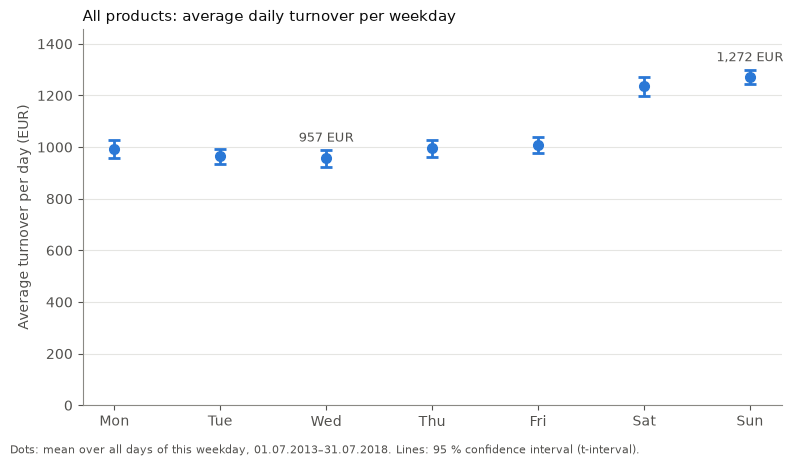

In [7]:
COLOR = "#2a78d6"   # one series -> one colour
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e5e5e2", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})

def plot_weekdays(ax, summary, title):
    x = np.arange(len(summary))
    err = [summary["mean"] - summary["ci_low"], summary["ci_high"] - summary["mean"]]
    ax.errorbar(x, summary["mean"], yerr=err, fmt="o", color=COLOR, markersize=7,
                elinewidth=2, capsize=4, capthick=2)
    ax.set_xticks(x)
    ax.set_xticklabels([d[:3] for d in summary.index])
    ax.set_ylim(bottom=0, top=summary["ci_high"].max() * 1.12)
    ax.set_title(title, loc="left", fontsize=11, color="#0b0b0b")

fig, ax = plt.subplots(figsize=(8, 4.5))
plot_weekdays(ax, summary_total, "All products: average daily turnover per weekday")
ax.set_ylabel("Average turnover per day (EUR)")
# Label only the highest and lowest weekday, not every point
for day in [summary_total["mean"].idxmax(), summary_total["mean"].idxmin()]:
    i = WEEKDAYS.index(day)
    ax.annotate(f"{summary_total.loc[day, 'mean']:,.0f} EUR", (i, summary_total.loc[day, "ci_high"]),
                textcoords="offset points", xytext=(0, 6), ha="center", fontsize=9, color="#52514e")
fig.text(0.01, -0.02, "Dots: mean over all days of this weekday, 01.07.2013–31.07.2018. Lines: 95 % confidence interval (t-interval).",
         fontsize=8, color="#52514e")
fig.tight_layout()
plt.show()

### 6b. One subplot per product group

The six groups sell very different amounts (bread sells much more than seasonal bread), so **each subplot has its own y-axis scale**. Compare the *shape* of the weekday pattern between groups, not the height of the dots across subplots.

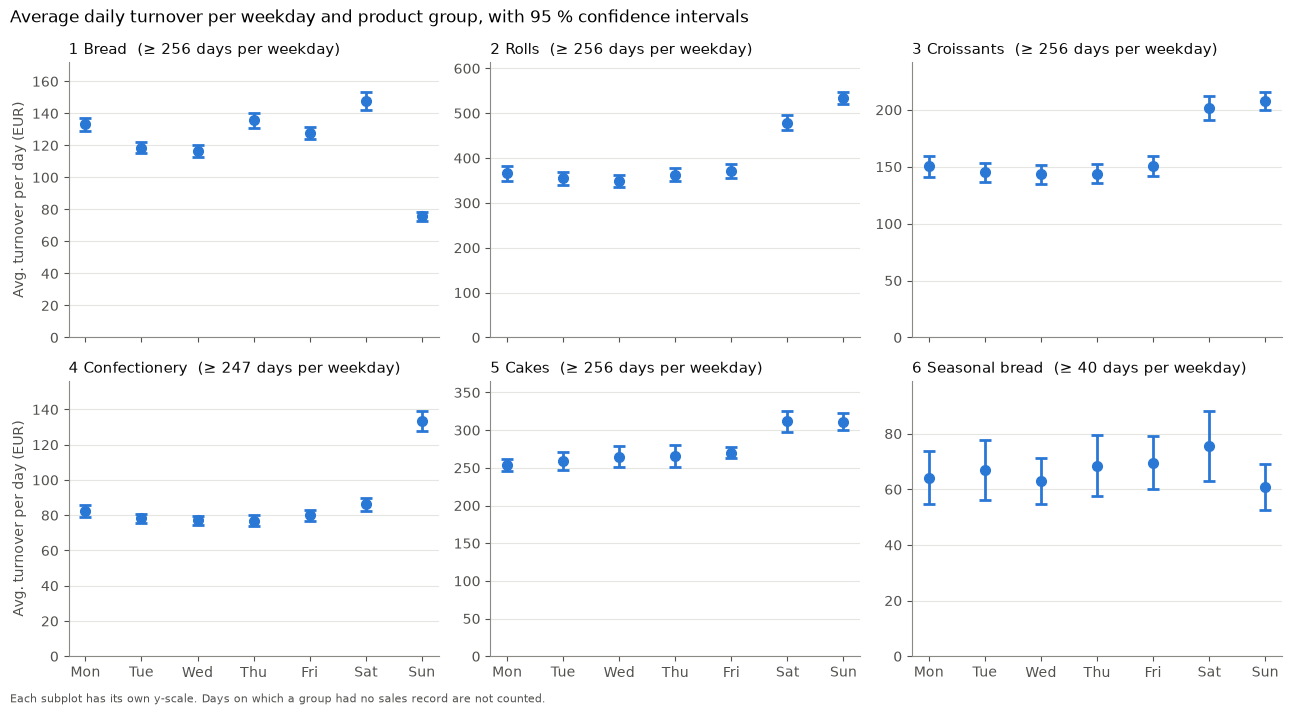

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for ax, ((nr, name), summary) in zip(axes.flat, summary_group.groupby(level=["Warengruppe", "group"])):
    summary = summary.droplevel(["Warengruppe", "group"])
    n_min = summary["n_days"].min()
    plot_weekdays(ax, summary, f"{nr} {name}  (≥ {n_min} days per weekday)")
for ax in axes[:, 0]:
    ax.set_ylabel("Avg. turnover per day (EUR)")
fig.suptitle("Average daily turnover per weekday and product group, with 95 % confidence intervals",
             x=0.01, ha="left", fontsize=12)
fig.text(0.01, -0.01, "Each subplot has its own y-scale. Days on which a group had no sales record are not counted.",
         fontsize=8, color="#52514e")
fig.tight_layout()
plt.show()

## 7. Relative to an average day (percent)

The canvas asks for the pattern in **percent relative to a normal day**. As a first step we divide each weekday mean by the mean of the seven weekday means (so every weekday counts equally). 100 % = an average day; 120 % = 20 % more turnover than an average day. The confidence interval is scaled the same way (this ignores the small uncertainty of the reference value itself).

In [8]:
def to_percent(summary):
    ref = summary["mean"].mean()
    return (summary[["mean", "ci_low", "ci_high"]] / ref * 100).round(0)

pct_total = to_percent(summary_total)["mean"].rename("All products")
pct_groups = summary_group.groupby(level="group", sort=False).apply(
    lambda s: to_percent(s.droplevel(["Warengruppe", "group"]))["mean"]
)
pct_table = pd.concat([pct_total.to_frame().T, pct_groups])
pct_table.columns = [c[:3] for c in pct_table.columns]
pct_table.astype(int).astype(str) + " %"

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
All products,94 %,91 %,90 %,94 %,95 %,116 %,120 %
Bread,109 %,97 %,96 %,111 %,105 %,121 %,62 %
Rolls,91 %,88 %,87 %,90 %,92 %,119 %,133 %
Croissants,92 %,89 %,88 %,88 %,92 %,123 %,127 %
Confectionery,94 %,89 %,88 %,88 %,91 %,98 %,152 %
Cakes,92 %,94 %,96 %,96 %,98 %,113 %,112 %
Seasonal bread,96 %,100 %,94 %,102 %,104 %,113 %,91 %


## 8. What we see

*(Written from the outputs above; if the data changes, re-check these statements.)*

- **All products:** the weekend is clearly the strongest part of the week. An average Sunday brings about 1,272 EUR and a Saturday about 1,235 EUR, compared with roughly 960–1,010 EUR on Monday to Friday (about +20 % vs. an average day on Sunday, about −10 % on Wednesday). The weekend intervals do not overlap with any weekday interval, so this difference is not chance. Monday to Friday overlap a lot and are hard to tell apart.
- **Rolls, croissants:** the same pattern as the total: Saturday and Sunday clearly higher (about +20 to +33 %), weekdays flat.
- **Bread is the exception:** Saturday is the best day, but **Sunday is by far the weakest** (about 76 EUR, 62 % of an average day). Tuesday and Wednesday are also lower than Monday and Thursday.
- **Confectionery:** flat from Monday to Saturday, then a strong peak on **Sunday** (about 152 % of an average day).
- **Cakes:** a mild rise over the week and higher on Saturday and Sunday (about +12 %); the two weekend days are about equal.
- **Seasonal bread:** only about 40 days per weekday, so the intervals are wide and all overlap. The data cannot show a clear weekday pattern for this group.

**What to check next:** the confidence intervals assume independent days and are therefore a bit optimistic; and the pattern may differ between years or between summer and the rest of the year (canvas question Q-b). Revenue also does not show demand on days when products were sold out.

## 9. Why do sales differ between weekdays? Possible factors and a central hypothesis

*(Week 3. This section explains the patterns above. The factors below are **possible explanations, not proven causes**: the sales data only shows *when* turnover is high, not *why*.)*

### 9a. Possible factors

| Factor | What it could explain | Fits the data? |
|---|---|---|
| **More free time at the weekend** (shopping trips, going into town or to the mall, leisure activities, visits) | More customers pass the branch on Saturday and Sunday, so most groups sell more | Yes: total, rolls, croissants and cakes are clearly higher on Saturday and Sunday |
| **Weekend breakfast at home** (fresh rolls and croissants for a long breakfast or brunch with family) | Strong weekend peak for rolls (+19 % / +33 %) and croissants (+23 % / +27 %) | Yes, especially on Sunday |
| **Shop opening hours** (bakeries may open on Sunday, while supermarkets and most other shops are closed) | On Saturday people buy bread for the weekend (bread is highest on Saturday, 121 %); on Sunday they eat what they bought before (bread only 62 %) | Yes: explains why bread is the only big group with a weak Sunday |
| **Afternoon coffee and cake, visits, small gifts on Sunday** | Confectionery peaks on Sunday only (152 %), cakes are high on both weekend days | Plausible |
| **Weekday routine** (commuters, work, school) | Monday–Friday are flat and similar to each other | Yes: weekday intervals overlap strongly |
| **Location and tourism** (e.g. visitors in summer, Kiel Week) | Weekend effect could be stronger in summer | Not yet checked (canvas question Q-b) |
| **Other calendar effects** (public holidays behave like a Sunday, school holidays, weather) | Can make single weekdays look higher or lower | Not yet checked; these are *confounders* that could mix with the weekday effect |
| **Supply side** (products sold out, price changes over the years) | Turnover may underestimate demand on busy days | Unknown: revenue does not show sold-out days |

### 9b. Central hypothesis

Proposed by the team: *Saturday is overall higher in all six product groups, because people have more time at the weekend to go shopping (town centre, malls etc.).*

**Checked against the outputs above:**

- **Supported:** on Saturday the average turnover is higher than on **every day from Monday to Friday in all six groups** (percent table in section 7, compared within each row: e.g. bread 121 % vs. at most 111 %, confectionery 98 % vs. at most 94 %).
- **Needs a more precise wording:**
  - Saturday is **not always the best day of the week**: for all products together, rolls, croissants and confectionery, **Sunday is even higher**. Saturday is the top day only for bread and seasonal bread (and about equal with Sunday for cakes).
  - For **confectionery**, Saturday is only slightly above Monday–Friday (98 % vs. 88–94 %); the big increase comes on Sunday.
  - For **seasonal bread**, the intervals are wide (only about 40 days per weekday) and overlap, so the data cannot confirm the Saturday effect for this group.

**Refined central hypothesis (to test in the next steps):**

> **H1:** In every product group, the average daily turnover on Saturday is higher than on a normal weekday (Monday–Friday), because customers have more free time for shopping on Saturday. On Sunday, turnover depends on the product: breakfast and treat products (rolls, croissants, confectionery) rise further, while bread drops, because people buy their bread for the weekend on Saturday.
>
> **H0 (null hypothesis):** Saturday turnover is not different from the Monday–Friday average.

**How we could test it:**

1. For each group, compute the **difference** Saturday minus Monday–Friday average, with a 95 % confidence interval. H1 is supported for a group if the interval lies completely above 0.
2. Repeat this **per year** and **summer vs. rest of the year**, to see whether the effect is stable or driven by tourism season.
3. Mark **public holidays** and **school holidays** and check whether the Saturday effect remains when these days are excluded.
4. Use the weekday (Saturday, Sunday, Monday–Friday) as a **feature** in the baseline model and check whether it improves the MAPE per product group on the validation data.

**Recommendation for the operations manager (preliminary):** bake more rolls, croissants and cakes on both weekend days, more bread on Saturday but clearly less on Sunday, and more confectionery mainly on Sunday.